<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/>

# Regression and Classification: Evaluating Classification Models
---
<small>© COPYRIGHT 2026 DECODED LIMITED. ALL RIGHTS RESERVED. Web: https://decoded.com/ </small>


---

### Summary

In this chapter we explore how classification models are evaluated and compared in real-world machine learning workflows. Through a combination of theory, hands-on exercises, and practical examples, we will examine how to train multiple classification models, validate their performance using cross-validation, and optimise them using hyperparameter tuning. We will focus particularly on evaluating models in imbalanced datasets using precision and recall, comparing models against baseline performance, and interpreting results in a policy or decision-making context.


### Learning Objectives

* Understand how classification models are trained and evaluated in a machine learning workflow
* Recognise the challenges posed by **imbalanced datasets** and why accuracy can be misleading
* Train multiple classification models including logistic regression, decision trees, and random forests
* Apply **train–test splitting** and understand the importance of evaluating models on unseen data
* Use **cross-validation** to estimate model performance and assess model stability
* Compare models using appropriate metrics such as **precision and recall**
* Perform **hyperparameter tuning using GridSearchCV** to optimise model performance
* Understand the purpose of **baseline models** and compare trained models against random prediction
* Interpret classification model performance using confusion matrices and evaluation metrics
* Connect model evaluation results to **practical decision-making contexts**



### Overview

[**Understanding the classification problem**](#classification_problem)

* What is the prediction task?
* Why is this a classification problem?
* What challenges arise when the dataset is imbalanced?
* *Challenge*: Explore the class distribution

[**Preparing data for model training**](#data_preparation)

* Why do we split data into training and test sets?
* What is stratified sampling?
* How does train–test splitting prevent data leakage?
* *Demo*: Use `train_test_split()` in `sklearn`

[**Training classification models**](#model_training)

* What are logistic regression, decision trees, and random forests?
* Why train multiple models?
* How do models learn patterns from training data?
* *Demo*: Train models using `sklearn` classifiers

[**Evaluating models with cross-validation**](#cross_validation)

* What is cross-validation?
* Why do we evaluate models across multiple folds?
* How do we interpret variation in model performance?
* *Challenge*: Compare cross-validation scores

[**Improving models with hyperparameter tuning**](#hyperparameter_tuning)

* What are hyperparameters?
* How does grid search help improve model performance?
* How does `GridSearchCV` work?
* *Demo*: Tune classification models using `GridSearchCV`

[**Comparing models objectively**](#model_comparison)

* How do we compare multiple trained models?
* Why visualise cross-validation scores?
* What does a boxplot of model performance tell us?
* *Challenge*: Compare model stability and performance

[**Using baseline models for context**](#baseline_models)

* What is a baseline model?
* Why compare models against random predictions?
* How do we implement a `DummyClassifier`?
* *Challenge*: Evaluate baseline performance

[**Evaluating the final model**](#final_model_evaluation)

* Why must the final model be evaluated on the test set?
* What are precision and recall?
* How do we interpret confusion matrix outcomes?
* *Challenge*: Interpret model predictions in context



### Introductions

#### Purpose: What is the aim of the content?

The purpose of this workshop is to develop a clear understanding of how classification models are evaluated and compared in practice. While training models is an important step in machine learning, selecting the most appropriate model requires careful evaluation using appropriate metrics and validation techniques. In this lesson, learners will explore how to compare multiple models, apply cross-validation, optimise models through hyperparameter tuning, and interpret performance metrics such as precision and recall. These skills are essential for building reliable models that support real-world decision-making.



#### Objectives: What will I learn?

* Understand the workflow for training and evaluating classification models
* Recognise the impact of class imbalance on model evaluation
* Train and compare multiple classification algorithms
* Apply cross-validation to estimate model performance
* Perform hyperparameter tuning using grid search
* Evaluate models using precision and recall metrics
* Implement baseline models for meaningful comparison
* Interpret classification outcomes using confusion matrices
* Connect model evaluation results to real-world decision contexts


#### Process: How will I learn this content?

Throughout the workshop, we will:

* explore concepts through short explanations and examples
* train and evaluate models using Python and `scikit-learn`
* compare model performance using visualisations and metrics
* complete guided exercises and challenges
* discuss how evaluation results inform real-world decisions



#### Applications: Why study this?

Classification models are widely used to support decision-making across many domains, including finance, healthcare, public policy, marketing, and social research. However, selecting a model based solely on accuracy can lead to misleading conclusions, particularly when datasets are imbalanced. Understanding how to properly evaluate classification models using metrics such as precision and recall allows analysts to assess the real impact of model predictions. These evaluation techniques help ensure that machine learning models provide meaningful insights and reliable support for policy, business, and operational decisions.





---
---
# Problem Statement
---
---




We are building a **classification model** to predict whether an individual or household is likely to experience **residential out-migration**. In this context, the target variable (Y) represents a binary outcome:

* **(Y = 1)** indicates that a person or household leaves the area (out-migration)
* **(Y = 0)** indicates that they remain in the area

The model uses a range of explanatory features to estimate the probability that an individual belongs to one of these two categories. These features may include demographic, economic, or housing-related characteristics that help explain patterns of residential mobility.

The purpose of this model is not simply to make predictions, but to **support policy decision-making**. In particular, the model is designed to help identify groups or areas where the risk of out-migration is higher. These insights can then be used to inform **targeted interventions under the Programme for Government**, such as initiatives aimed at retaining graduates, supporting housing stability, or strengthening regional economic opportunities.

Because policy resources are limited, the model must be evaluated carefully to ensure that interventions are directed toward individuals who are genuinely at risk of leaving. This is why metrics such as **precision and recall** become important. Precision helps ensure that resources are not wasted on individuals who would not have left anyway, while recall measures how effectively the model identifies those who are truly at risk.

In this lesson, we will explore how classification models can be trained, validated, and evaluated in order to support this type of evidence-based policy decision-making.

---
---
# Selecting Our Evaluation Metric For This Problem
---
---


## Policy Context

We are predicting **residential out-migration (Y=1)** to inform targeted interventions under the Programme for Government.

Public funds are limited. Every intervention must be defensible.

---
## Cost of Errors
---

### False Positive (FP)

We intervene, but the resident would have stayed anyway.

**Cost:**

* Deadweight loss (wasted subsidy)
* Reduced funds for genuine cases
* Audit and accountability risk

This is an **immediate, measurable fiscal cost**.

### False Negative (FN)

We fail to intervene, and the resident leaves.

**Cost:**

* Long-term economic and demographic impact
* Harder to measure directly in the short term

This is a **strategic, longer-term cost**.

---
---

## Why Precision Is Prioritised
---
---

Precision answers:

> “When we intervene, how often are we correct?”

High precision ensures:

* Interventions are tightly targeted
* Public money is not wasted
* Decisions withstand scrutiny

In a budget-constrained public sector environment, avoiding expenditure on ineffective interventions is crucial.

---
## Policy Trade-Off
---

We accept:

* Some at-risk residents may not be identified (lower recall)

In exchange for:

* High confidence that funded interventions are justified

This is a deliberate choice to prioritise **resource efficiency and accountability**.



## Imports for the Notebook

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, cross_validate, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score,
    precision_recall_curve, auc
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from sklearn.metrics import average_precision_score, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


### Importing the Dataset

In [ ]:
df = pd.read_csv('classification_example.csv')

In [ ]:
df.head()

,Unnamed: 0.1,Unnamed: 0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,residential_OM
0,0,0,-0.567936,0.646493,-2.059645,-0.832422,0.849646,0.173328,-0.761963,2.022970,0.410998,0.218720,-0.374238,0.286062,0
1,1,1,-0.673446,0.118050,-0.845845,-0.791772,0.083840,-0.495486,0.779919,0.697871,-1.205888,0.888974,0.257651,1.236992,0
2,2,2,0.446600,-0.594476,-0.470616,-0.584384,0.230415,-1.348161,1.426533,-0.496649,-1.171799,-1.837643,-0.073882,0.955191,0
3,3,3,-0.722612,-0.067864,-0.282173,-1.050625,-0.108521,-1.102196,-0.620782,-0.340066,-1.142077,0.097478,-2.220361,-0.277137,0
4,4,4,-0.444133,0.096995,-0.956933,-0.137247,0.247397,-1.503364,0.724007,0.593222,-0.335741,0.264456,0.862074,-0.335543,0


In [ ]:
X = df.drop(['residential_OM','Unnamed: 0','Unnamed: 0.1'],axis=1)

In [ ]:
X.head()

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12
0,-0.567936,0.646493,-2.059645,-0.832422,0.849646,0.173328,-0.761963,2.022970,0.410998,0.218720,-0.374238,0.286062
1,-0.673446,0.118050,-0.845845,-0.791772,0.083840,-0.495486,0.779919,0.697871,-1.205888,0.888974,0.257651,1.236992
2,0.446600,-0.594476,-0.470616,-0.584384,0.230415,-1.348161,1.426533,-0.496649,-1.171799,-1.837643,-0.073882,0.955191
3,-0.722612,-0.067864,-0.282173,-1.050625,-0.108521,-1.102196,-0.620782,-0.340066,-1.142077,0.097478,-2.220361,-0.277137
4,-0.444133,0.096995,-0.956933,-0.137247,0.247397,-1.503364,0.724007,0.593222,-0.335741,0.264456,0.862074,-0.335543


In [ ]:
y = df["residential_OM"]

##  Looking at the Class Distribution


It appears that the ddataset is imbalanced, so as mentioned earlier the - accuracy is not a good metric to evaluate the model performance. We will use precision as our primary metric to evaluate the model performance.

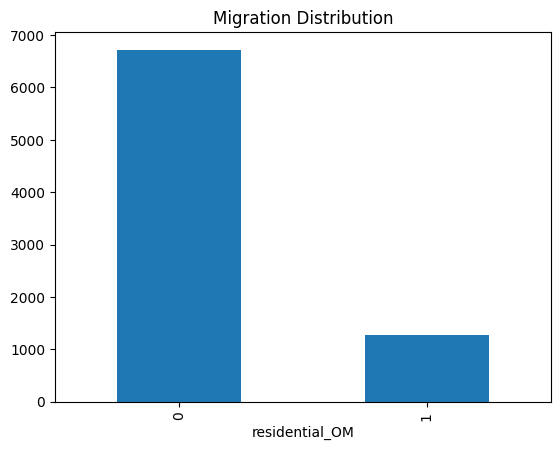

In [ ]:
y.value_counts().plot(kind='bar')
plt.title('Migration Distribution')
plt.show()

## Train/Test Split


Now we will split the data into a training set and a test set. The training set will be used to train the model, and the test set will be used to evaluate the model's performance on unseen data. Remember:

- stratify the split to maintain the class distribution in both sets. Since the dataset is imbalanced
- do not toouch the test set in any way until the final evaluation step. The test set should only be used once to evaluate the final model performance.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, stratify=y, random_state=42)

## Model Fitting


Let us first instantiate our classifcation models

In [ ]:
model_lr = LogisticRegression()
model_dt = DecisionTreeClassifier(random_state=42)
model_rf = RandomForestClassifier(random_state=42)

we will fit our models

In [ ]:
model_lr.fit(X_train, y_train)
model_dt.fit(X_train, y_train)
model_rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In the next section we jump straight to cross validation as the single train/test split is not enough to evaluate the models. (remeber, our  model might get lucky with the train/test split so we do k-folds cross validation to get a better estimate of the model performance)

## Cross-Validation


### unlike regression we have to consider class balance so we will use stratified k folds instead of the usual kfolds

In [ ]:
strat_kfolds = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [ ]:

cv_scores_lr = cross_validate(model_lr, X_train, y_train, cv=strat_kfolds, scoring=("precision","recall" ))

In [ ]:
cv_results_lr = pd.DataFrame(cv_scores_lr)

In [ ]:
print(cv_results_lr.describe())

       fit_time  score_time  test_precision  test_recall
count  5.000000    5.000000        5.000000     5.000000
mean   0.010003    0.002516        0.881649     0.204240
std    0.014523    0.001305        0.079479     0.036320
min    0.001588    0.001434        0.755556     0.150838
25%    0.001889    0.001451        0.860465     0.189944
50%    0.002665    0.002412        0.913043     0.205556
75%    0.008367    0.002652        0.914894     0.234637
max    0.035507    0.004633        0.964286     0.240223


In [ ]:

cv_scores_dt = cross_validate(model_dt, X_train, y_train, cv=strat_kfolds, scoring=("precision","recall"))


In [ ]:
cv_results_dt = pd.DataFrame(cv_scores_dt)

In [ ]:
print(cv_results_dt.describe())

       fit_time  score_time  test_precision  test_recall
count  5.000000    5.000000        5.000000     5.000000
mean   0.047206    0.001578        0.671229     0.689721
std    0.007238    0.000136        0.021333     0.022036
min    0.042231    0.001452        0.649485     0.659218
25%    0.043212    0.001500        0.651042     0.675978
50%    0.044715    0.001510        0.670157     0.698324
75%    0.045972    0.001640        0.690058     0.700000
max    0.059900    0.001787        0.695402     0.715084


In [ ]:
cv_scores_rf = cross_validate(model_rf, X_train, y_train, cv=strat_kfolds, scoring=("precision","recall"))


In [ ]:
cv_results_rf = pd.DataFrame(cv_scores_rf)

In [ ]:
print(cv_results_rf.describe())

       fit_time  score_time  test_precision  test_recall
count  5.000000    5.000000        5.000000     5.000000
mean   0.641528    0.007422        0.959202     0.648430
std    0.005826    0.000076        0.016303     0.048121
min    0.632441    0.007325        0.939850     0.575419
25%    0.640010    0.007388        0.949580     0.631285
50%    0.642223    0.007410        0.960630     0.655556
75%    0.645676    0.007457        0.962617     0.681564
max    0.647289    0.007529        0.983333     0.698324


### Rather than try to manually cross reference the precision scores across the different models, we can use boxplots to visualise the distribution of precision scores across the different models.

In [ ]:
cv_results = pd.concat([cv_results_lr["test_precision"],cv_results_dt["test_precision"],cv_results_rf["test_precision"]],axis=1)

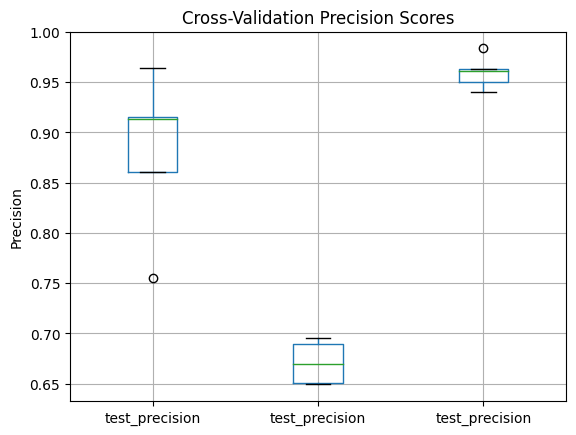

In [ ]:

cv_results.boxplot()


plt.title('Cross-Validation Precision Scores')
plt.ylabel('Precision')
plt.show()


Based on intital fits, the decision decision tree appears to have a much harder time being consistent in its precision scores. But remember, the intial fits are just that - initial. We will need to do hyperparameter tuning to see if we can improve the performance of our models

# Hyperparameter Tuning

In [ ]:
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

In [ ]:
grid_lr = GridSearchCV(
    LogisticRegression(),
    param_grid_lr,
    cv=strat_kfolds,
    scoring="average_precision"
)

In [ ]:
grid_lr.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LogisticRegression(),
             param_grid={'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l1', 'l2'],
                         'solver': ['liblinear']},
             scoring='average_precision')

In [ ]:
best_model_lr = grid_lr.best_estimator_

In [ ]:
print('Best parameters:', grid_lr.best_params_)

Best parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear'}


In [ ]:
print('Best PR AUC (Logistic Regression):', grid_lr.best_score_)

Best PR AUC (Logistic Regression): 0.5146850534314105


In [ ]:
param_grid_dt = {
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}


In [ ]:
grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid_dt,
    cv=strat_kfolds,
    scoring="average_precision"
)

In [ ]:
grid_dt.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [None, 5, 10, 20],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='average_precision')

In [ ]:
best_model_dt = grid_dt.best_estimator_

In [ ]:
print('Best parameters:', grid_dt.best_params_)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}


In [ ]:
print('Best CV PR AUC (Decision Tree):', grid_dt.best_score_)

Best CV PR AUC (Decision Tree): 0.7189905697405736


In [ ]:
param_grid_rf= {
    'n_estimators': [10],            # number of trees in the forest
    'max_depth': [None, 10],          # maximum depth of each tree (controls complexity)
    'min_samples_split': [2, 5],      # minimum number of samples required to split a node
    'min_samples_leaf': [1, 2]        # minimum number of samples required in a leaf node
}



In [ ]:
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=strat_kfolds,
    scoring="average_precision"
)


In [ ]:
grid_rf.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [None, 10], 'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5], 'n_estimators': [10]},
             scoring='average_precision')

In [ ]:
best_model_rf = grid_rf.best_estimator_

In [ ]:
print('Best parameters:', grid_rf.best_params_)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 10}


In [ ]:
print('Best CV PR AUC (Random Forest):', grid_rf.best_score_)

Best CV PR AUC (Random Forest): 0.817302183675752


In [ ]:
std = grid_rf.cv_results_["std_test_score"][grid_rf.best_index_]
print(std)

0.022676688518868896


In [ ]:
means = [
    grid_lr.best_score_,
    grid_dt.best_score_,
    grid_rf.best_score_
]

In [ ]:
stds = [
    grid_lr.cv_results_["std_test_score"][grid_lr.best_index_],
    grid_dt.cv_results_["std_test_score"][grid_dt.best_index_],
    grid_rf.cv_results_["std_test_score"][grid_rf.best_index_]
]

<BarContainer object of 3 artists>

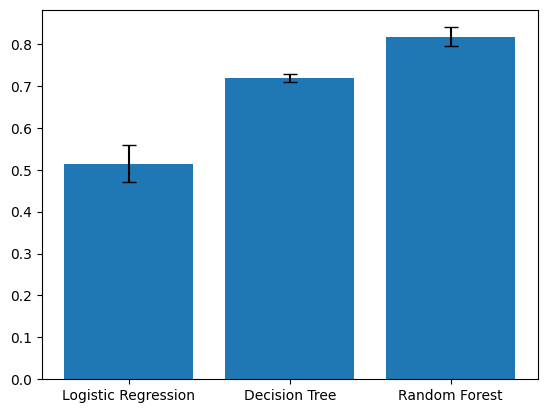

In [ ]:
models = ["Logistic Regression", "Decision Tree", "Random Forest"]
plt.bar(models, means, yerr=stds, capsize=5)

---
##  Model Evaluation For Classification
---

how do we know that are model has learned anything at all? a great way is to create a baseline model model that just makes random prediction and see how our model performs against that baseline.

In [ ]:
dummy = DummyClassifier(strategy="stratified", random_state=42)

In [ ]:
dummy.fit(X_train, y_train)

DummyClassifier(random_state=42, strategy='stratified')

In [ ]:
y_dummy_pred = dummy.predict(X_test)

In [ ]:
print("Dummy Accuracy:", accuracy_score(y_test, y_dummy_pred))

Dummy Accuracy: 0.7325


In [ ]:
print("Dummy Precision:", precision_score(y_test, y_dummy_pred, zero_division=0))

Dummy Precision: 0.16580310880829016


In [ ]:
print("Dummy Recall:", recall_score(y_test, y_dummy_pred, zero_division=0))

Dummy Recall: 0.16666666666666666


Text(0.5, 1.0, 'Confusion Matrix (Normalised)')

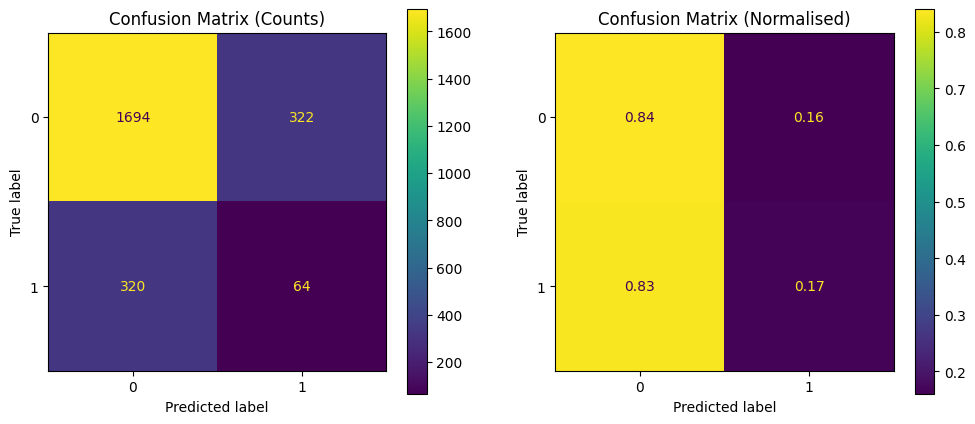

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))


ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_dummy_pred,
    ax=axes[0],
    values_format="d"
)
axes[0].set_title("Confusion Matrix (Counts)")


# Normalised
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_dummy_pred,
    normalize="true",
    ax=axes[1],
    values_format=".2f"
)
axes[1].set_title("Confusion Matrix (Normalised)")




# Policy Interpretation

Random guessing results show that:

when the model predicts a resident will leave, it is correct only about 17% of the time (precision ~17%).

Only ~17% of true leavers would be identified.

Most funding would be misdirected.

This is not a viable policy tool.

---
# Evaluating The Best Model
---

we import the best model from the previous section

In [ ]:
best_model = best_model_rf

In [ ]:
y_pred = best_model.predict(X_test)

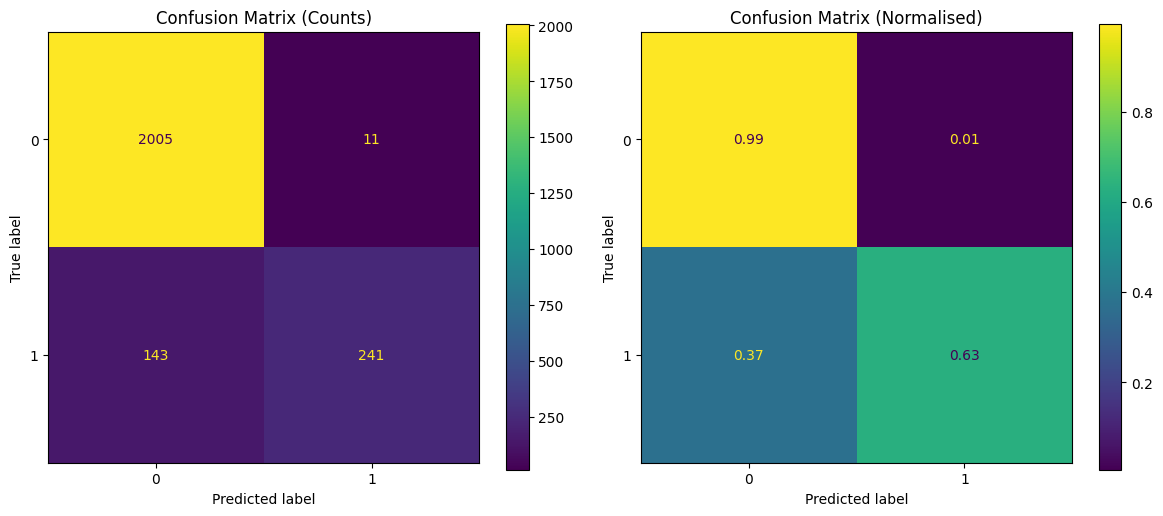

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Raw counts
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    ax=axes[0],
    values_format="d"
)
axes[0].set_title("Confusion Matrix (Counts)")

# Normalised
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    normalize="true",
    ax=axes[1],
    values_format=".2f"
)
axes[1].set_title("Confusion Matrix (Normalised)")

plt.tight_layout()
plt.show()

In [ ]:
print('Precision:', precision_score(y_test, y_pred))

Precision: 0.9563492063492064


In [ ]:
print('Recall:', recall_score(y_test, y_pred))

Recall: 0.6276041666666666



# Precision

When the model predicts that someone is at risk of leaving, it is correct about 96% of the time.

So the misallocation of financial resources is very low.

### Policy framing

The model results in very little wasted intervention spending.

# Recall

The model correctly identifies about 63% of the individuals who actually leave.

### policy framing

The model captures most at-risk individuals but does not detect all of them.

The remaining 37% missed may still leave without intervention.

### So the trade-off is clear

The model prioritises accuracy of intervention over identifying every possible leaver. As we'd hoped, the model is very good at targeting interventions to those who are truly at risk, but it does not capture every single case. This is a common and acceptable trade-off in many real-world applications, especially when resources are limited and the cost of false positives is high.


---
# Further Consideration: Adding Uncertainty Estimates To Our Predictions
---

As we mentioned in the Regression notebook, using a single value (point estimate) to evaluate model performance can be misleading. we use bootstrapping to measure the uncertainty in precision scores to get a better understanding of the model performance in the case the test set is slightly different than the one we have.

In [ ]:
rng = np.random.default_rng(42)

n_boot = 5000
n = len(y_test)

boot_precisions = np.empty(n_boot)

# convert to numpy arrays to allow fancy indexing reliably
y_true = np.asarray(y_test)
y_hat = np.asarray(y_pred)

for b in range(n_boot):
    idx = rng.integers(0, n, size=n)  # sample indices with replacement
    boot_precisions[b] = precision_score(y_true[idx], y_hat[idx], zero_division=0)

ci_low, ci_high = np.percentile(boot_precisions, [2.5, 97.5])

print(f"Precision (bootstrap 95% CI): [{ci_low:.4f}, {ci_high:.4f}]")

Precision (bootstrap 95% CI): [0.9301, 0.9798]


In simple terms, this means:

If we tested the model on another similar dataset, the precision might change a little.
The confidence interval shows how much it could realistically change.

So instead of saying:
The model is correct exactly 96% of the time,

Our test set is just one sample of data.

If you collected another similar dataset:
- Precision might be 93%
- or 96%
- or 98%

The interval shows the likely range.

we say:
It is probably between 93% and 98% correct, depending on the sample we happened to test it on.



---
# Further Considerations - Thresholding
---

At a threshold of 0.5 default threshold. the model achieves precision of 0.96, meaning only 4% of funded interventions would be misallocated. This reflects strong fiscal discipline. Lets us look at at an example of how we can improve of test accuracy by tuning the threshold

In [ ]:
from sklearn.model_selection import cross_val_predict

y_probas_forest = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=strat_kfolds,
    method="predict_proba"
)

In [ ]:
y_scores_forest = y_probas_forest[:, 1]

In [ ]:
precisions, recalls, thresholds = precision_recall_curve(
    y_train,
    y_scores_forest
)

In [ ]:
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Metric")
plt.legend()
plt.show()

In [ ]:
target_precision = 0.975

In [ ]:
valid = precisions[:-1] >= target_precision

In [ ]:
best_idx = np.argmax(recalls[:-1][valid])

In [ ]:

chosen_threshold = thresholds[valid][best_idx]
chosen_precision = precisions[:-1][valid][best_idx]
chosen_recall = recalls[:-1][valid][best_idx]


In [ ]:

print("Chosen threshold:", chosen_threshold)
print("Precision at threshold:", chosen_precision)
print("Recall at threshold:", chosen_recall)

In [ ]:
y_train_pred_custom = (y_scores_forest >= chosen_threshold).astype(int)

In [ ]:
y_test_scores = best_model.predict_proba(X_test)[:, 1]

Test precision: 0.9710743801652892
Test recall: 0.6119791666666666


In [ ]:
# 3. Apply threshold chosen from training/CV
y_test_pred_custom = (y_test_scores >= chosen_threshold).astype(int)

In [ ]:
print("Test precision:", precision_score(y_test, y_test_pred_custom))
print("Test recall:", recall_score(y_test, y_test_pred_custom))